# 04 BM25

## Objetivos

* Implementar BM25 y comparar su ranking con el de TF-IDF + coseno sobre la misma colección de documentos.
* Calcular el aporte de cada término en BM25, identificar qué controlan $k_1$ y $b$, y justificar un cambio de posición usando las estadísticas de los documentos.

**1. Carga el corpus de Project Gutenberg**

Utilice el corpus de Project Gutenberg y el preprocesamiento de la práctica anterior.

Recupere una tabla con los campos **Identificador de documento | Título | Texto**

Calcule la columna `tokens` para la tabla, con lista de tokens normalizados de cada documento.

Calcula DF e IDF.

In [5]:
import copy
import math
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import gutenberg
from scipy import sparse
from scipy.sparse.linalg import norm as sp_norm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download("gutenberg", quiet=True)

# Carga los 18 libros completos del corpus Gutenberg
corpus_docs = {
    fileid: gutenberg.raw(fileid)
    for fileid in gutenberg.fileids()
}

print(f"Total de documentos cargados: {len(corpus_docs)}")

Total de documentos cargados: 18


In [6]:
# Preprocesamiento de la práctica anterior: minúsculas + tokens alfanuméricos
def preprocess_text(text):
    return re.findall(r"\b\w+\b", text.lower())

def obtener_titulo(fid, texto):
    # La primera línea de los textos de NLTK suele ser "[Título by Autor año]"
    m = re.match(r"\s*\[([^\]]+)\]", texto)
    return m.group(1).strip() if m else fid

docs = pd.DataFrame({
    "doc_id": list(corpus_docs.keys()),
    "titulo": [obtener_titulo(f, t) for f, t in corpus_docs.items()],
    "texto":  list(corpus_docs.values()),
})
docs = docs.sort_values("doc_id").reset_index(drop=True)   # IDs tratados como cadenas, orden estable
docs["tokens"] = docs["texto"].apply(preprocess_text)
docs["longitud"] = docs["tokens"].apply(len)

doc_ids = docs["doc_id"].tolist()
titulos = dict(zip(docs["doc_id"], docs["titulo"]))
textos = dict(zip(docs["doc_id"], docs["texto"]))
N = len(docs)

vista = docs[["doc_id", "titulo"]].copy()
vista["texto (inicio)"] = docs["texto"].str.replace(r"\s+", " ", regex=True).str[:70] + "..."
vista["Nº de tokens"] = docs["longitud"]
display(vista)
print(f"Documentos: {N} | Vocabulario: {len(set(t for d in docs['tokens'] for t in d)):,} términos")
print(f"Longitud mínima / media / máxima: {docs.longitud.min():,} / {docs.longitud.mean():,.1f} / {docs.longitud.max():,}")

,doc_id,titulo,texto (inicio),Nº de tokens
0,austen-emma.txt,Emma by Jane Austen 1816,[Emma by Jane Austen 1816] VOLUME I CHAPTER I ...,161983
1,austen-persuasion.txt,Persuasion by Jane Austen 1818,[Persuasion by Jane Austen 1818] Chapter 1 Sir...,84167
2,austen-sense.txt,Sense and Sensibility by Jane Austen 1811,[Sense and Sensibility by Jane Austen 1811] CH...,120787
3,bible-kjv.txt,The King James Bible,[The King James Bible] The Old Testament of th...,854046
4,blake-poems.txt,Poems by William Blake 1789,[Poems by William Blake 1789] SONGS OF INNOCEN...,6936
5,bryant-stories.txt,Stories to Tell to Children by Sara Cone Bryan...,[Stories to Tell to Children by Sara Cone Brya...,46703
6,burgess-busterbrown.txt,The Adventures of Buster Bear by Thornton W. B...,[The Adventures of Buster Bear by Thornton W. ...,16363
7,carroll-alice.txt,Alice's Adventures in Wonderland by Lewis Carr...,[Alice's Adventures in Wonderland by Lewis Car...,27336
8,chesterton-ball.txt,The Ball and The Cross by G.K. Chesterton 1909,[The Ball and The Cross by G.K. Chesterton 190...,82867
9,chesterton-brown.txt,The Wisdom of Father Brown by G. K. Chesterton...,[The Wisdom of Father Brown by G. K. Chesterto...,73288


Documentos: 18 | Vocabulario: 42,099 términos
Longitud mínima / media / máxima: 6,936 / 122,178.8 / 854,046


In [7]:
# DF: nº de documentos en que aparece cada término (una vez por documento)
df = Counter()
for toks in docs["tokens"]:
    df.update(set(toks))

# IDF de BM25 (Okapi, con +1 dentro del log para que nunca sea negativo)
idf_bm25 = {t: math.log(1 + (N - n + 0.5) / (n + 0.5)) for t, n in df.items()}

# IDF de TF-IDF (el mismo de la práctica 03, scikit-learn con smooth_idf=False)
idf_tfidf = {t: math.log(N / n) + 1 for t, n in df.items()}

muestra = ["the", "man", "god", "sea", "whale", "denmark", "ahab", "harpoon"]
display(pd.DataFrame({
    "df": [df[t] for t in muestra],
    "IDF BM25": [round(idf_bm25[t], 4) for t in muestra],
    "IDF TF-IDF": [round(idf_tfidf[t], 4) for t in muestra],
}, index=muestra))

,df,IDF BM25,IDF TF-IDF
the,18,0.0267,1.0000
man,18,0.0267,1.0000
god,16,0.1411,1.1178
sea,16,0.1411,1.1178
whale,6,1.0726,2.0986
denmark,3,1.6917,2.7918
ahab,2,2.0281,3.1972
harpoon,2,2.0281,3.1972


**2. Benchmarking**

Seleccione **ocho consultas en el idioma del corpus** y registra en una línea qué busca el usuario con cada una. Incluye términos muy frecuentes, términos poco frecuentes, y consultas de distintas longitudes. Usa $df$ para justificar las elecciones.

Para **TF-IDF + coseno** conserva la representación dispersa de la matriz.

Para **BM25** define $k_1=1.2$, $b=0.75$. Mantén intactas las estadísticas de la colección al cambiar de consulta.

Para cada consulta, ordena por puntuación descendente y desempata por `doc_id` ascendente (trata los IDs como cadenas en ambos métodos). Presenta hasta diez documentos con score positivo por método. Una consulta sin términos en el vocabulario produce dos listas vacías.

In [9]:
consultas = {
    "q1": ("whale",
           "Cualquier texto que trate de ballenas (término raro, una sola palabra)."),
    "q2": ("ahab harpoon",
           "El capitán obsesionado con la ballena y su arpón (dos términos muy raros)."),
    "q3": ("the man",
           "Consulta casi vacía de información: dos palabras presentes en todo el corpus."),
    "q4": ("love death wife lady sir",
           "Temas de novela y drama en general (cinco términos frecuentes, df alto)."),
    "q5": ("white whale captain ship sea",
           "Una expedición marítima y la caza de una ballena (mezcla de términos comunes y raros)."),
    "q6": ("king ghost murder prince denmark",
           "Una obra teatral con intriga de corte, fantasmas y asesinato."),
    "q7": ("god lord israel king people",
           "Pasajes religiosos o bíblicos sobre Dios y el pueblo de Israel."),
    "q8": ("marriage ball gentleman sisters estate family fortune",
           "Novelas de costumbres sobre matrimonio, bailes y herencias (consulta larga, 7 términos)."),
}
consultas_tokens = {k: preprocess_text(v[0]) for k, v in consultas.items()}

# Justificación con df: cada término de cada consulta con su df e IDF
filas = []
for k, toks in consultas_tokens.items():
    filas.append({
        "Consulta": k,
        "Texto": consultas[k][0],
        "Nº términos": len(toks),
        "df por término": ", ".join(f"{t}={df.get(t, 0)}" for t in toks),
        "Qué busca el usuario": consultas[k][1],
    })
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(filas))

,Consulta,Texto,Nº términos,df por término,Qué busca el usuario
0,q1,whale,1,whale=6,"Cualquier texto que trate de ballenas (término raro, una sola palabra)."
1,q2,ahab harpoon,2,"ahab=2, harpoon=2",El capitán obsesionado con la ballena y su arpón (dos términos muy raros).
2,q3,the man,2,"the=18, man=18",Consulta casi vacía de información: dos palabras presentes en todo el corpus.
3,q4,love death wife lady sir,5,"love=15, death=18, wife=15, lady=15, sir=15","Temas de novela y drama en general (cinco términos frecuentes, df alto)."
4,q5,white whale captain ship sea,5,"white=16, whale=6, captain=9, ship=12, sea=16",Una expedición marítima y la caza de una ballena (mezcla de términos comunes y raros).
5,q6,king ghost murder prince denmark,5,"king=15, ghost=9, murder=9, prince=11, denmark=3","Una obra teatral con intriga de corte, fantasmas y asesinato."
6,q7,god lord israel king people,5,"god=16, lord=15, israel=5, king=15, people=17",Pasajes religiosos o bíblicos sobre Dios y el pueblo de Israel.
7,q8,marriage ball gentleman sisters estate family fortune,7,"marriage=12, ball=12, gentleman=12, sisters=12, estate=12, family=13, fortune=12","Novelas de costumbres sobre matrimonio, bailes y herencias (consulta larga, 7 términos)."


In [10]:
# ---------- TF-IDF + coseno (representación dispersa) ----------
vec = TfidfVectorizer(
    analyzer=lambda tokens: tokens,   # usa los tokens ya procesados
    use_idf=True, smooth_idf=False, sublinear_tf=False, norm=None,
)
X = vec.fit_transform(docs["tokens"].tolist())        # matriz CSR documentos x términos
doc_norms = sp_norm(X, axis=1)
print("Tipo de X:", type(X).__name__, "| forma:", X.shape,
      f"| no ceros: {X.nnz:,} ({X.nnz / (X.shape[0] * X.shape[1]):.1%} de la matriz densa)")

def ranking_tfidf(tokens, top_k=10):
    """Ranking por coseno. Solo documentos con score > 0; desempata por doc_id ascendente."""
    q = vec.transform([tokens])                       # usa vocabulario e IDF del corpus
    if q.nnz == 0:                                    # ningún término está en el vocabulario
        return []
    dots = (X @ q.T).toarray().ravel()
    cos = dots / (doc_norms * sp_norm(q))
    cand = [(doc_ids[i], float(cos[i])) for i in np.nonzero(cos > 0)[0]]
    cand.sort(key=lambda x: (-x[1], x[0]))
    return cand[:top_k]

# Verificación contra scikit-learn
for k, toks in consultas_tokens.items():
    q = vec.transform([toks])
    ref = cosine_similarity(q, X).ravel()
    mio = dict(ranking_tfidf(toks, top_k=N))
    assert all(abs(mio.get(doc_ids[i], 0.0) - ref[i]) < 1e-9 for i in range(N))
print("Coseno disperso explícito == cosine_similarity de scikit-learn (tolerancia 1e-9).")

Tipo de X: csr_matrix | forma: (18, 42099) | no ceros: 121,988 (16.1% de la matriz densa)
Coseno disperso explícito == cosine_similarity de scikit-learn (tolerancia 1e-9).


In [11]:
# ---------- BM25 ----------
class BM25:
    def __init__(self, doc_ids, docs_tokens, k1=1.2, b=0.75):
        """
        Índice BM25. Las estadísticas de la colección (N, longitudes, avgdl, TF, DF, IDF)
        se calculan UNA sola vez aquí; buscar o puntuar nunca las modifica.
        :param doc_ids: lista de identificadores (cadenas).
        :param docs_tokens: lista de listas de tokens, alineada con doc_ids.
        """
        self.k1, self.b = k1, b
        self.doc_ids = list(doc_ids)
        self.N = len(self.doc_ids)
        self.doc_len = {d: len(t) for d, t in zip(doc_ids, docs_tokens)}
        self.avgdl = sum(self.doc_len.values()) / self.N
        self.tf = {d: Counter(t) for d, t in zip(doc_ids, docs_tokens)}
        self.df = Counter()
        self.index = {}                                # índice invertido: término -> [doc_id, ...]
        for d, c in self.tf.items():
            self.df.update(c.keys())
            for term in c:
                self.index.setdefault(term, []).append(d)
        self.idf = {t: math.log(1 + (self.N - n + 0.5) / (n + 0.5)) for t, n in self.df.items()}

    def con_parametros(self, k1, b):
        """Misma colección y mismas estadísticas, otros k1 y b (no se recalcula nada)."""
        otro = copy.copy(self)
        otro.k1, otro.b = k1, b
        return otro

    def aporte(self, term, doc_id):
        """Aporte BM25 de un término a un documento: IDF * f(k1+1) / (f + k1(1-b+b|d|/avgdl))."""
        f = self.tf[doc_id].get(term, 0)
        if f == 0:
            return 0.0
        dl = self.doc_len[doc_id]
        num = f * (self.k1 + 1.0)
        den = f + self.k1 * (1.0 - self.b + self.b * dl / self.avgdl)
        return self.idf[term] * num / den

    def score_document(self, query_tokens, doc_id):
        # términos de consulta sin repetir; los que no están en el vocabulario aportan 0
        return sum(self.aporte(t, doc_id) for t in dict.fromkeys(query_tokens) if t in self.idf)

    def search(self, query_tokens, top_k=10):
        """Lista [(doc_id, score)] con score > 0, orden score desc y doc_id asc."""
        terminos = [t for t in dict.fromkeys(query_tokens) if t in self.idf]
        if not terminos:
            return []
        candidatos = {d for t in terminos for d in self.index[t]}   # vía índice invertido
        res = [(d, self.score_document(terminos, d)) for d in candidatos]
        res = [(d, s) for d, s in res if s > 0]
        res.sort(key=lambda x: (-x[1], x[0]))
        return res[:top_k]

bm25 = BM25(doc_ids, docs["tokens"].tolist(), k1=1.2, b=0.75)
print(f"N = {bm25.N} | avgdl = {bm25.avgdl:,.1f} | k1 = {bm25.k1} | b = {bm25.b}")

# Comprobaciones: IDF/DF coinciden con los de la sección 1 y la consulta fuera del vocabulario da listas vacías
assert all(bm25.df[t] == df[t] and abs(bm25.idf[t] - idf_bm25[t]) < 1e-12 for t in df)
assert bm25.search(["zzzxqj"]) == [] and ranking_tfidf(["zzzxqj"]) == []
print("Consulta sin términos del vocabulario -> TF-IDF: [] | BM25: []")

# Las estadísticas no cambian entre consultas
snap = (bm25.N, bm25.avgdl, dict(bm25.df))
for toks in consultas_tokens.values():
    bm25.search(toks)
assert snap == (bm25.N, bm25.avgdl, dict(bm25.df))
print("Estadísticas de la colección intactas después de las 8 consultas.")

N = 18 | avgdl = 122,178.8 | k1 = 1.2 | b = 0.75
Consulta sin términos del vocabulario -> TF-IDF: [] | BM25: []
Estadísticas de la colección intactas después de las 8 consultas.


In [12]:
# Costo por consulta (ms) de cada método: 8 consultas x 200 repeticiones
def medir(fn, reps=200):
    t0 = time.perf_counter()
    for _ in range(reps):
        for toks in consultas_tokens.values():
            fn(toks)
    return (time.perf_counter() - t0) / (reps * len(consultas_tokens)) * 1000

print(f"TF-IDF + coseno (matriz dispersa): {medir(ranking_tfidf):.3f} ms/consulta")
print(f"BM25 (índice invertido):           {medir(bm25.search):.3f} ms/consulta")

TF-IDF + coseno (matriz dispersa): 0.842 ms/consulta
BM25 (índice invertido):           0.063 ms/consulta


**3. Compara los rankings**

Muestra por consulta una tabla como esta. Usa los IDs para comparar.

| Posición | ID y título TF-IDF | Coseno | ID y título BM25 | Score BM25 |
|---:|---|---:|---|---:|
| 1 | … | … | … | … |

Calcula cuántos IDs comparten los dos top 10 con $|T_{\mathrm{TFIDF}}\cap T_{\mathrm{BM25}}|$. Reporta también el tamaño real de cada lista y el primer documento de cada método. Dos listas pueden tener muchos IDs en común y ordenarlos de forma distinta.

Elige una consulta y dos documentos que cambien de posición o cuya distancia en el ranking cambie. Registra $|d|$, $f(t,d)$, $df(t)$ y el aporte BM25 de cada término de consulta para ambos documentos. Relaciona esas cifras con la saturación, la longitud o la rareza del término. Usa los scores de cada método para explicar su propio ranking.

In [ ]:
# Tablas comparativas por consulta
def etiqueta(doc_id):
    return f"{doc_id} — {titulos[doc_id]}"

def tabla_comparacion(nombre, top_k=10):
    toks = consultas_tokens[nombre]
    r_tf, r_bm = ranking_tfidf(toks, top_k), bm25.search(toks, top_k)
    filas = []
    for i in range(top_k):
        a = r_tf[i] if i < len(r_tf) else None
        b = r_bm[i] if i < len(r_bm) else None
        filas.append({
            "Posición": i + 1,
            "ID y título TF-IDF": etiqueta(a[0]) if a else "—",
            "Coseno": round(a[1], 4) if a else None,
            "ID y título BM25": etiqueta(b[0]) if b else "—",
            "Score BM25": round(b[1], 4) if b else None,
        })
    return pd.DataFrame(filas), r_tf, r_bm

resumen = []
for nombre in consultas:
    tabla, r_tf, r_bm = tabla_comparacion(nombre)
    print(f"\n=== {nombre}: «{consultas[nombre][0]}» ===")
    display(tabla)
    T_tf, T_bm = [d for d, _ in r_tf], [d for d, _ in r_bm]
    resumen.append({
        "Consulta": nombre,
        "|T_TFIDF|": len(T_tf),
        "|T_BM25|": len(T_bm),
        "|T_TFIDF ∩ T_BM25|": len(set(T_tf) & set(T_bm)),
        "Primero TF-IDF": T_tf[0] if T_tf else "—",
        "Primero BM25": T_bm[0] if T_bm else "—",
        "Mismo orden en el top 10": T_tf == T_bm,
        "Posiciones iguales": sum(a == b for a, b in zip(T_tf, T_bm)),
    })

print("\n=== Resumen de solapamiento de los top 10 ===")
resumen = pd.DataFrame(resumen)
display(resumen)


=== q1: «whale» ===


,Posición,ID y título TF-IDF,Coseno,ID y título BM25,Score BM25
0,1,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,0.1194,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,2.3561
1,2,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,0.0065,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,2.2685
2,3,shakespeare-hamlet.txt — The Tragedie of Hamlet by William Shakespeare 1599,0.0015,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,1.8931
3,4,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,0.0008,shakespeare-hamlet.txt — The Tragedie of Hamlet by William Shakespeare 1599,1.8706
4,5,chesterton-ball.txt — The Ball and The Cross by G.K. Chesterton 1909,0.0005,chesterton-ball.txt — The Ball and The Cross by G.K. Chesterton 1909,1.6216
5,6,bible-kjv.txt — The King James Bible,0.0001,bible-kjv.txt — The King James Bible,0.7381
6,7,—,NaN,—,NaN
7,8,—,NaN,—,NaN
8,9,—,NaN,—,NaN
9,10,—,NaN,—,NaN



=== q2: «ahab harpoon» ===


,Posición,ID y título TF-IDF,Coseno,ID y título BM25,Score BM25
0,1,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,0.0616,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,8.7978
1,2,bible-kjv.txt — The King James Bible,0.0020,bible-kjv.txt — The King James Bible,4.1696
2,3,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,0.0002,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,1.9985
3,4,—,NaN,—,NaN
4,5,—,NaN,—,NaN
5,6,—,NaN,—,NaN
6,7,—,NaN,—,NaN
7,8,—,NaN,—,NaN
8,9,—,NaN,—,NaN
9,10,—,NaN,—,NaN



=== q3: «the man» ===


,Posición,ID y título TF-IDF,Coseno,ID y título BM25,Score BM25
0,1,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,0.5238,bible-kjv.txt — The King James Bible,0.1172
1,2,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,0.4910,chesterton-thursday.txt — The Man Who Was Thursday by G. K. Chesterton 1908,0.1172
2,3,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,0.4857,chesterton-ball.txt — The Ball and The Cross by G.K. Chesterton 1909,0.1172
3,4,chesterton-brown.txt — The Wisdom of Father Brown by G. K. Chesterton 1914,0.4776,chesterton-brown.txt — The Wisdom of Father Brown by G. K. Chesterton 1914,0.1172
4,5,chesterton-thursday.txt — The Man Who Was Thursday by G. K. Chesterton 1908,0.4473,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,0.1171
5,6,bible-kjv.txt — The King James Bible,0.4472,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,0.1170
6,7,chesterton-ball.txt — The Ball and The Cross by G.K. Chesterton 1909,0.4392,milton-paradise.txt — Paradise Lost by John Milton 1667,0.1170
7,8,blake-poems.txt — Poems by William Blake 1789,0.4384,"edgeworth-parents.txt — The Parent's Assistant, by Maria Edgeworth",0.1170
8,9,carroll-alice.txt — Alice's Adventures in Wonderland by Lewis Carroll 1865,0.3883,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,0.1170
9,10,"edgeworth-parents.txt — The Parent's Assistant, by Maria Edgeworth",0.3625,austen-emma.txt — Emma by Jane Austen 1816,0.1170


... (8 outputs left out)


=== q8: «marriage ball gentleman sisters estate family fortune» ===


,Posición,ID y título TF-IDF,Coseno,ID y título BM25,Score BM25
0,1,austen-persuasion.txt — Persuasion by Jane Austen 1818,0.0123,austen-persuasion.txt — Persuasion by Jane Austen 1818,5.7999
1,2,austen-sense.txt — Sense and Sensibility by Jane Austen 1811,0.0117,austen-emma.txt — Emma by Jane Austen 1816,5.7605
2,3,austen-emma.txt — Emma by Jane Austen 1816,0.0078,austen-sense.txt — Sense and Sensibility by Jane Austen 1811,5.6026
3,4,"edgeworth-parents.txt — The Parent's Assistant, by Maria Edgeworth",0.0069,whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855,5.0052
4,5,chesterton-brown.txt — The Wisdom of Father Brown by G. K. Chesterton 1914,0.0062,"edgeworth-parents.txt — The Parent's Assistant, by Maria Edgeworth",4.9359
5,6,shakespeare-macbeth.txt — The Tragedie of Macbeth by William Shakespeare 1603,0.0060,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,4.0610
6,7,shakespeare-hamlet.txt — The Tragedie of Hamlet by William Shakespeare 1599,0.0054,chesterton-thursday.txt — The Man Who Was Thursday by G. K. Chesterton 1908,3.8941
7,8,chesterton-ball.txt — The Ball and The Cross by G.K. Chesterton 1909,0.0052,chesterton-brown.txt — The Wisdom of Father Brown by G. K. Chesterton 1914,3.5769
8,9,chesterton-thursday.txt — The Man Who Was Thursday by G. K. Chesterton 1908,0.0040,melville-moby_dick.txt — Moby Dick by Herman Melville 1851,3.5429
9,10,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,0.0025,shakespeare-hamlet.txt — The Tragedie of Hamlet by William Shakespeare 1599,3.3777



=== Resumen de solapamiento de los top 10 ===


,Consulta,|T_TFIDF|,|T_BM25|,|T_TFIDF ∩ T_BM25|,Primero TF-IDF,Primero BM25,Mismo orden en el top 10,Posiciones iguales
0,q1,6,6,6,melville-moby_dick.txt,melville-moby_dick.txt,False,4
1,q2,3,3,3,melville-moby_dick.txt,melville-moby_dick.txt,True,3
2,q3,10,10,8,whitman-leaves.txt,bible-kjv.txt,False,1
3,q4,10,10,4,shakespeare-macbeth.txt,austen-persuasion.txt,False,0
4,q5,10,10,8,melville-moby_dick.txt,melville-moby_dick.txt,False,2
5,q6,10,10,7,shakespeare-hamlet.txt,shakespeare-hamlet.txt,False,1
6,q7,10,10,8,bible-kjv.txt,bible-kjv.txt,False,1
7,q8,10,10,8,austen-persuasion.txt,austen-persuasion.txt,False,1


### Lectura de los rankings

* **Listas cortas.** `q1` (`whale`) y `q2` (`ahab harpoon`) solo tienen 6 y 3 documentos con score positivo, porque los demás no contienen los términos. En `q2` los dos métodos coinciden exactamente (Moby Dick, Biblia, Leaves of Grass). En `q1` coinciden los 6 documentos, pero solo 4 posiciones son iguales: el orden de Hamlet y Leaves of Grass se invierte.
* **El primer documento coincide en 6 de 8 consultas.** Ambos métodos ponen a Moby Dick primero en `q1`, `q2` y `q5`, a Hamlet en `q6`, a la Biblia en `q7` y a Persuasion en `q8`. Difieren en `q3` y `q4`.
* **Muchos IDs en común no implica el mismo orden.** En `q5`, `q7` y `q8` comparten 8 de 10 documentos, pero solo coinciden 2, 1 y 1 posiciones respectivamente. En `q6` comparten 7.
* **Consultas con términos frecuentes.** En `q4` (`love death wife lady sir`) los top 10 comparten solo 4 documentos y ninguna posición coincide. Con $df$ entre 15 y 18, el IDF de BM25 es pequeño (≈0.03–0.20) y la puntuación depende sobre todo de la saturación de frecuencia y de la longitud. En `q3` (`the man`) el IDF de BM25 es 0.0267 para ambos términos y los scores de los 10 primeros documentos son casi idénticos (≈0.117), así que el orden depende de diferencias mínimas. TF-IDF + coseno, en cambio, ordena por la geometría del vector.

### Dos documentos que cambian de posición

Consulta **q5**: `white whale captain ship sea`. Se comparan *Persuasion* (Austen) y *Stories to Tell to Children* (Bryant). En TF-IDF Persuasion está segundo y Bryant cuarto; en BM25 Bryant sube al tercer lugar y Persuasion baja al octavo. El orden relativo se invierte y la distancia pasa de 2 a 5 posiciones.

Para cada documento se registran $|d|$, $f(t,d)$, $df(t)$ y el aporte de cada término:

$$\text{aporte}(t,d)=IDF(t)\cdot\frac{f(t,d)\,(k_1+1)}{f(t,d)+K},\qquad K=k_1\left(1-b+b\frac{|d|}{\text{avgdl}}\right)$$

El factor $\frac{f(k_1+1)}{f+K}$ es la parte de saturación y nunca supera $k_1+1=2.2$.

In [ ]:
# ---- Elegimos una consulta y dos documentos cuya posición cambia entre métodos ----
consulta_sel = "q5"
toks_sel = list(dict.fromkeys(consultas_tokens[consulta_sel]))
d_a, d_b = "austen-persuasion.txt", "bryant-stories.txt"

full_tf = ranking_tfidf(consultas_tokens[consulta_sel], top_k=N)
full_bm = bm25.search(consultas_tokens[consulta_sel], top_k=N)
pos_tf = {d: (i + 1, s) for i, (d, s) in enumerate(full_tf)}
pos_bm = {d: (i + 1, s) for i, (d, s) in enumerate(full_bm)}

display(pd.DataFrame({
    "Documento": [etiqueta(d) for d in (d_a, d_b)],
    "|d| (tokens)": [bm25.doc_len[d] for d in (d_a, d_b)],
    "Posición TF-IDF": [pos_tf[d][0] for d in (d_a, d_b)],
    "Coseno": [round(pos_tf[d][1], 4) for d in (d_a, d_b)],
    "Posición BM25": [pos_bm[d][0] for d in (d_a, d_b)],
    "Score BM25": [round(pos_bm[d][1], 4) for d in (d_a, d_b)],
}))
print(f"Distancia entre ambos documentos: TF-IDF = {abs(pos_tf[d_a][0]-pos_tf[d_b][0])} posiciones, "
      f"BM25 = {abs(pos_bm[d_a][0]-pos_bm[d_b][0])} posiciones (el orden relativo se invierte).")
print(f"Consulta {consulta_sel}: «{consultas[consulta_sel][0]}» | avgdl = {bm25.avgdl:,.1f} | k1 = {bm25.k1} | b = {bm25.b}")

# ---- Aporte BM25 de cada término ----
def desglose_bm25(modelo, tokens, doc_id):
    dl = modelo.doc_len[doc_id]
    K = modelo.k1 * (1 - modelo.b + modelo.b * dl / modelo.avgdl)      # denominador de longitud
    filas = []
    for t in dict.fromkeys(tokens):
        if t not in modelo.idf:
            continue
        f = modelo.tf[doc_id].get(t, 0)
        sat = f * (modelo.k1 + 1) / (f + K) if f else 0.0              # parte de saturación (máx. k1+1)
        filas.append({"Término": t, "df(t)": modelo.df[t], "IDF": round(modelo.idf[t], 4),
                      "f(t,d)": f, "f(k1+1)/(f+K)": round(sat, 4),
                      "Aporte BM25": round(modelo.aporte(t, doc_id), 4)})
    tabla = pd.DataFrame(filas)
    return tabla, K

for d in (d_a, d_b):
    tabla, K = desglose_bm25(bm25, consultas_tokens[consulta_sel], d)
    print(f"\n--- BM25 · {etiqueta(d)} ---")
    print(f"|d| = {bm25.doc_len[d]:,} | |d|/avgdl = {bm25.doc_len[d]/bm25.avgdl:.3f} | K = k1(1-b+b|d|/avgdl) = {K:.4f}")
    display(tabla)
    print(f"Suma de aportes = {tabla['Aporte BM25'].sum():.4f} | score del ranking = {pos_bm[d][1]:.4f}")

# ---- Mismo documento visto desde TF-IDF + coseno ----
def desglose_coseno(tokens, doc_id):
    q = vec.transform([tokens])
    d = X[doc_ids.index(doc_id)]
    filas = []
    for t in dict.fromkeys(tokens):
        j = vec.vocabulary_.get(t)
        if j is None:
            continue
        qi, di = q[0, j], d[0, j]
        filas.append({"Término": t, "f(t,d)": bm25.tf[doc_id].get(t, 0),
                      "q_i": round(qi, 4), "d_i": round(di, 4), "Producto parcial": round(qi * di, 4)})
    dot = float((q @ d.T)[0, 0])
    return pd.DataFrame(filas), dot, sp_norm(q), sp_norm(d)

for d in (d_a, d_b):
    tabla, dot, nq, nd = desglose_coseno(consultas_tokens[consulta_sel], d)
    print(f"\n--- TF-IDF · {etiqueta(d)} ---")
    display(tabla)
    print(f"Producto punto = {dot:,.2f} | ||q|| = {nq:.4f} | ||d|| = {nd:,.2f} | coseno = {dot/(nq*nd):.4f}")

,Documento,|d| (tokens),Posición TF-IDF,Coseno,Posición BM25,Score BM25
0,austen-persuasion.txt — Persuasion by Jane Austen 1818,84167,2,0.0330,8,2.8785
1,bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918,46703,4,0.0094,3,4.8447


Distancia entre ambos documentos: TF-IDF = 2 posiciones, BM25 = 5 posiciones (el orden relativo se invierte).
Consulta q5: «white whale captain ship sea» | avgdl = 122,178.8 | k1 = 1.2 | b = 0.75

--- BM25 · austen-persuasion.txt — Persuasion by Jane Austen 1818 ---
|d| = 84,167 | |d|/avgdl = 0.689 | K = k1(1-b+b|d|/avgdl) = 0.9200


,Término,df(t),IDF,"f(t,d)",f(k1+1)/(f+K),Aporte BM25
0,white,16,0.1411,5,1.8581,0.2621
1,whale,6,1.0726,0,0.0000,0.0000
2,captain,9,0.6931,303,2.1933,1.5203
3,ship,12,0.4187,6,1.9075,0.7987
4,sea,16,0.1411,21,2.1077,0.2973


Suma de aportes = 2.8784 | score del ranking = 2.8785

--- BM25 · bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918 ---
|d| = 46,703 | |d|/avgdl = 0.382 | K = k1(1-b+b|d|/avgdl) = 0.6440


,Término,df(t),IDF,"f(t,d)",f(k1+1)/(f+K),Aporte BM25
0,white,16,0.1411,45,2.1690,0.3060
1,whale,6,1.0726,16,2.1149,2.2685
2,captain,9,0.6931,2,1.6641,1.1535
3,ship,12,0.4187,5,1.9490,0.8161
4,sea,16,0.1411,20,2.1314,0.3007


Suma de aportes = 4.8448 | score del ranking = 4.8447

--- TF-IDF · austen-persuasion.txt — Persuasion by Jane Austen 1818 ---


,Término,"f(t,d)",q_i,d_i,Producto parcial
0,white,5,1.1178,5.5889,6.2472
1,whale,0,2.0986,0.0000,0.0000
2,captain,303,1.6931,513.0236,868.6245
3,ship,6,1.4055,8.4328,11.8520
4,sea,21,1.1178,23.4734,26.2382


Producto punto = 912.96 | ||q|| = 3.4271 | ||d|| = 8,063.65 | coseno = 0.0330

--- TF-IDF · bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918 ---


,Término,"f(t,d)",q_i,d_i,Producto parcial
0,white,45,1.1178,50.3002,56.2248
1,whale,16,2.0986,33.5778,70.4668
2,captain,2,1.6931,3.3863,5.7335
3,ship,5,1.4055,7.0273,9.8767
4,sea,20,1.1178,22.3557,24.9888


Producto punto = 167.29 | ||q|| = 3.4271 | ||d|| = 5,179.73 | coseno = 0.0094


In [ ]:
# Verificación a mano de un aporte (término `whale` en Bryant) con la fórmula, sin usar la clase
d, t = "bryant-stories.txt", "whale"
n_t, f, dl = df[t], bm25.tf[d][t], bm25.doc_len[d]
idf_t = math.log(1 + (N - n_t + 0.5) / (n_t + 0.5))
K = 1.2 * (1 - 0.75 + 0.75 * dl / bm25.avgdl)
aporte_mano = idf_t * f * (1.2 + 1) / (f + K)
print(f"IDF = {idf_t:.4f} | K = {K:.4f} | aporte a mano = {aporte_mano:.4f} | aporte de la clase = {bm25.aporte(t, d):.4f}")
assert abs(aporte_mano - bm25.aporte(t, d)) < 1e-12

IDF = 1.0726 | K = 0.6440 | aporte a mano = 2.2685 | aporte de la clase = 2.2685


**Por qué TF-IDF pone a Persuasion por encima de Bryant (con sus propios scores).** El coseno de Persuasion es 0.0330 y el de Bryant 0.0094. Casi todo el producto punto de Persuasion (868.6 de 912.96, un 95 %) viene de `captain`, que aparece 303 veces: el TF es lineal, así que cada repetición suma peso completo ($d_i=513.0$). Bryant tiene un producto punto de 167.3, pese a tener `whale` 16 veces, el término más raro de la consulta. Las normas de los documentos ($\|d\|=8{,}063.7$ y $5{,}179.7$) no compensan esa diferencia.

**Por qué BM25 los invierte.**

* **Saturación.** Persuasion repite `captain` 303 veces, pero su factor de saturación es 2.193, casi el tope de 2.2. Su aporte es 1.520, solo 1.32 veces el de Bryant, que lo menciona 2 veces (1.154). Las 301 repeticiones extra casi no suman.
* **Rareza.** `whale` tiene $df=6$ (IDF 1.073, el mayor de la consulta). Persuasion no lo contiene y aporta 0; Bryant lo contiene 16 veces y aporta 2.2685, casi la mitad de su score (4.8447). El resto de términos aportan montos parecidos a ambos.
* **Longitud.** Bryant es más corta que la media ($|d|/\text{avgdl}=0.38$ frente a 0.69), así que su $K$ es menor (0.644 frente a 0.920) y sus frecuencias bajas rinden más: `captain` con $f=2$ ya alcanza una saturación de 1.664.

Resultado: el score de BM25 es 2.8785 para Persuasion y 4.8447 para Bryant, y cae de posición 2 a 8 mientras Bryant sube del 4 al 3.

**4. Identifica el efecto de los parámetros**

Mantén fijos la colección y el preprocesamiento. Escoge una consulta con coincidencias en documentos de distintas longitudes y frecuencias.

| Ejecución | $k_1$ | $b$ | Qué examinar |
|---|---:|---:|---|
| Base | 1.2 | 0.75 | Posiciones y aportes de referencia |
| Sin ajuste por longitud | 1.2 | 0.00 | Cambios en documentos más cortos o más largos que la media |
| Mayor efecto de las repeticiones | 2.0 | 0.75 | Cambios en el aporte de términos con frecuencias distintas |

Muestra las posiciones de los mismos documentos en las tres configuraciones. Si no se mueven, compara sus aportes por término y explica por qué el cambio de puntuación no alteró su orden.

Se mantienen fijos la colección y el preprocesamiento. Se usa la consulta **q5** (`white whale captain ship sea`) porque hay coincidencias en documentos de longitudes muy distintas (desde Hamlet, con $|d|/\text{avgdl}=0.25$, hasta la Biblia, con 6.99) y con frecuencias que van de 0 a más de mil repeticiones. Los tres modelos comparten las mismas estadísticas de la colección; solo cambian $k_1$ y $b$.

In [ ]:
# ---- Efecto de k1 y b: colección y preprocesamiento fijos ----
consulta_par = "q5"
toks_par = consultas_tokens[consulta_par]
configs = {
    "Base (k1=1.2, b=0.75)":              bm25.con_parametros(1.2, 0.75),
    "Sin ajuste por longitud (b=0)":      bm25.con_parametros(1.2, 0.00),
    "Mayor efecto de repeticiones (k1=2)": bm25.con_parametros(2.0, 0.75),
}
rankings = {n: m.search(toks_par, top_k=N) for n, m in configs.items()}
posiciones = {n: {d: i + 1 for i, (d, _) in enumerate(r)} for n, r in rankings.items()}
puntajes = {n: dict(r) for n, r in rankings.items()}

nombres = list(configs)
orden_base = [d for d, _ in rankings[nombres[0]]]
tabla_pos = pd.DataFrame({
    "Documento": orden_base,
    "|d|/avgdl": [round(bm25.doc_len[d] / bm25.avgdl, 2) for d in orden_base],
    "Pos. base": [posiciones[nombres[0]][d] for d in orden_base],
    "Pos. b=0": [posiciones[nombres[1]][d] for d in orden_base],
    "Pos. k1=2": [posiciones[nombres[2]][d] for d in orden_base],
    "Score base": [round(puntajes[nombres[0]][d], 3) for d in orden_base],
    "Score b=0": [round(puntajes[nombres[1]][d], 3) for d in orden_base],
    "Score k1=2": [round(puntajes[nombres[2]][d], 3) for d in orden_base],
})
tabla_pos["Cambia"] = (tabla_pos["Pos. base"] != tabla_pos["Pos. b=0"]) | (tabla_pos["Pos. base"] != tabla_pos["Pos. k1=2"])
print(f"Consulta {consulta_par}: «{consultas[consulta_par][0]}»")
display(tabla_pos)

# Aportes por término de documentos seleccionados en las tres configuraciones
def tabla_aportes(doc_id):
    filas = []
    for t in dict.fromkeys(toks_par):
        fila = {"Término": t, "f(t,d)": bm25.tf[doc_id].get(t, 0)}
        for n, m in configs.items():
            fila[n.split(" (")[0]] = round(m.aporte(t, doc_id), 4)
        filas.append(fila)
    fila = {"Término": "SUMA", "f(t,d)": ""}
    for n, m in configs.items():
        fila[n.split(" (")[0]] = round(m.score_document(toks_par, doc_id), 4)
    filas.append(fila)
    return pd.DataFrame(filas)

for d in ["bible-kjv.txt", "bryant-stories.txt", "whitman-leaves.txt", "melville-moby_dick.txt"]:
    print(f"\n--- Aportes · {etiqueta(d)} (|d| = {bm25.doc_len[d]:,}) ---")
    display(tabla_aportes(d))

Consulta q5: «white whale captain ship sea»


,Documento,|d|/avgdl,Pos. base,Pos. b=0,Pos. k1=2,Score base,Score b=0,Score k1=2,Cambia
0,melville-moby_dick.txt,1.79,1,1,1,5.407,5.415,7.356,False
1,whitman-leaves.txt,1.04,2,2,3,4.847,4.859,6.214,True
2,bryant-stories.txt,0.38,3,4,2,4.845,4.486,6.218,True
3,bible-kjv.txt,6.99,4,3,4,3.628,4.718,4.486,True
4,shakespeare-hamlet.txt,0.25,5,9,7,3.161,2.548,3.833,True
5,chesterton-ball.txt,0.68,6,5,6,3.133,2.976,3.863,True
6,chesterton-brown.txt,0.60,7,6,5,2.952,2.906,3.929,True
7,austen-persuasion.txt,0.69,8,7,8,2.878,2.830,3.788,True
8,edgeworth-parents.txt,1.40,9,8,9,2.649,2.723,3.376,True
9,chesterton-thursday.txt,0.48,10,10,10,2.401,2.133,2.894,False



--- Aportes · bible-kjv.txt — The King James Bible (|d| = 854,046) ---


,Término,"f(t,d)",Base,Sin ajuste por longitud,Mayor efecto de repeticiones
0,white,75,0.2853,0.3055,0.3692
1,whale,3,0.7381,1.6856,0.6903
2,captain,139,1.4559,1.5119,1.9271
3,ship,71,0.8429,0.9059,1.0878
4,sea,400,0.3053,0.3094,0.4119
5,SUMA,,3.6276,4.7182,4.4863



--- Aportes · bryant-stories.txt — Stories to Tell to Children by Sara Cone Bryant 1918 (|d| = 46,703) ---


,Término,"f(t,d)",Base,Sin ajuste por longitud,Mayor efecto de repeticiones
0,white,45,0.3060,0.3023,0.4134
1,whale,16,2.2685,2.1952,3.0156
2,captain,2,1.1535,0.9531,1.3532
3,ship,5,0.8161,0.7429,1.0341
4,sea,20,0.3007,0.2928,0.4017
5,SUMA,,4.8447,4.4862,6.2180



--- Aportes · whitman-leaves.txt — Leaves of Grass by Walt Whitman 1855 (|d| = 126,605) ---


,Término,"f(t,d)",Base,Sin ajuste por longitud,Mayor efecto de repeticiones
0,white,89,0.3061,0.3062,0.4137
1,whale,5,1.8931,1.9031,2.2808
2,captain,19,1.4320,1.4343,1.8765
3,ship,79,0.9070,0.9074,1.2243
4,sea,192,0.3084,0.3084,0.4188
5,SUMA,,4.8467,4.8595,6.2141



--- Aportes · melville-moby_dick.txt — Moby Dick by Herman Melville 1851 (|d| = 218,621) ---


,Término,"f(t,d)",Base,Sin ajuste por longitud,Mayor efecto de repeticiones
0,white,281,0.3083,0.3091,0.4185
1,whale,1226,2.3561,2.3575,3.2096
2,captain,329,1.5161,1.5194,2.0595
3,ship,518,0.9178,0.9190,1.2485
4,sea,455,0.3091,0.3096,0.4203
5,SUMA,,5.4074,5.4145,7.3563


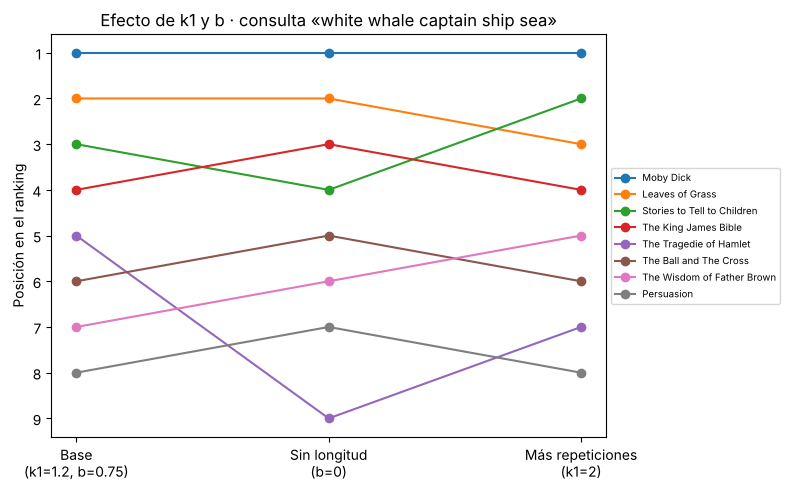

In [ ]:
# Posiciones de los mismos documentos en las tres configuraciones
fig, ax = plt.subplots(figsize=(8, 5))
x = [0, 1, 2]
for d in orden_base[:8]:
    ys = [posiciones[n][d] for n in nombres]
    ax.plot(x, ys, marker="o", label=titulos[d].split(" by ")[0][:28])
ax.set_xticks(x)
ax.set_xticklabels(["Base\n(k1=1.2, b=0.75)", "Sin longitud\n(b=0)", "Más repeticiones\n(k1=2)"])
ax.invert_yaxis()
ax.set_ylabel("Posición en el ranking")
ax.set_title(f"Efecto de k1 y b · consulta «{consultas[consulta_par][0]}»")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### Interpretación

**Sin ajuste por longitud ($b=0$).** Con $b=0$ el factor de longitud desaparece ($K=k_1$) y solo cambian los documentos lejos de la media.

* *La Biblia* ($|d|/\text{avgdl}=6.99$) deja de ser penalizada: su aporte por `whale` (3 apariciones) sube de 0.738 a 1.686 y su score de 3.628 a 4.718. Pasa de la posición 4 a la 3 y adelanta a Bryant.
* *Bryant* (0.38) pierde la ventaja de ser corta: su score baja de 4.845 a 4.486 (`captain` pasa de 1.154 a 0.953) y cae de la posición 3 a la 4.
* *Hamlet* (0.25) baja de 3.161 a 2.548 y cae de la posición 5 a la 9.
* *Leaves of Grass* ($|d|/\text{avgdl}=1.04$) casi no cambia (4.847 → 4.859) porque su longitud es casi la media y $1-b+b|d|/\text{avgdl}\approx 1$.

**Mayor efecto de las repeticiones ($k_1=2$).** Un $k_1$ mayor sube el tope de saturación de 2.2 a 3.0 y hace que cada repetición adicional siga sumando por más tiempo. Todos los scores suben, pero ganan más los términos con IDF alto. Bryant sube de la posición 3 a la 2 y adelanta a Leaves of Grass: su `whale` ($f=16$, IDF 1.073) pasa de 2.269 a 3.016 (+0.747), mientras que el de Leaves of Grass ($f=5$) solo sube de 1.893 a 2.281 (+0.388). Es un cambio por muy poco: 6.2180 frente a 6.2141, porque ya eran casi iguales en la base (4.8447 frente a 4.8467).

**Un documento que no se mueve: Moby Dick.** Es primero en las tres configuraciones, aunque su score cambia (5.407 → 5.415 con $b=0$, y 5.407 → 7.356 con $k_1=2$).

* Con $b=0$ casi no cambia porque sus frecuencias son tan altas que la saturación ya está en el tope. `whale` ($f=1226$) aporta 2.356 frente a un máximo de $IDF\cdot(k_1+1)=2.360$. Cuando $f\gg K$, el término $K$ casi no influye, así que la longitud de Moby Dick (1.79 veces la media) da igual.
* Con $k_1=2$ su score sube casi 2 puntos, pero el segundo lugar sube más de uno (de 4.847 a 6.218). La diferencia con el segundo pasa de 0.56 a 1.14 puntos, y el orden se conserva.
* La razón de fondo es que su `whale` (aporte 2.356 en la base) es el mayor de la colección para el término de mayor IDF, y ningún otro documento acumula suficiente en el resto de términos para alcanzarlo.

**Resumen de qué controla cada parámetro.**

* $b$ regula cuánto pesa la longitud: con $b=0$ ganan los documentos largos (Biblia) y pierden los cortos (Bryant, Hamlet). Los documentos de longitud cercana a la media no se ven afectados.
* $k_1$ regula la saturación: con valores altos, la frecuencia sigue importando más, y se benefician los términos raros con varias repeticiones. Con valores bajos, repetir un término 300 o 3 veces rinde casi lo mismo.

## Conclusiones

* BM25 y TF-IDF + coseno recuperan los mismos documentos cuando la consulta tiene términos raros y distintivos (`q1`, `q2`, `q5`, `q6`, `q7`, `q8` coinciden en el primer resultado), pero ordenan distinto el resto de la lista.
* TF-IDF crece linealmente con la frecuencia, y el coseno solo corrige la longitud mediante la norma del vector. BM25 satura la frecuencia y normaliza explícitamente por la longitud, controlando ambos con $k_1$ y $b$.
* Con consultas de términos muy frecuentes (`q3`, `q4`) los rankings divergen mucho y los scores de BM25 quedan casi empatados, ya que el IDF es cercano a cero. Son consultas poco informativas.
* En esta colección de solo 18 documentos, muy dispares en longitud (de 6,936 a 854,046 tokens), la normalización por longitud es especialmente influyente.